# Electricity Consumption Prediction — SI Lab Project

**Dataset:** UCI Individual Household Electric Power Consumption (real historical measurements).  
**Goal:** Use current-hour household readings to predict the next hour's average active power, compare regression models, and create an illustrative multi-hour forecast and bill estimate.

## 1. Install/import libraries

In [12]:
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import ttest_rel

RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power_consumption.zip"
FEATURES = ["power_kw", "reactive_power", "voltage", "intensity", "kitchen_submeter_wh", "laundry_submeter_wh", "water_heater_ac_submeter_wh"]
print("Imports complete")

Imports complete


## 2. Download the real dataset

In [13]:
# Use the correct, updated direct download URL
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00235/household_power_consumption.zip"

response = requests.get(DATA_URL, timeout=120)
response.raise_for_status()
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    data_file = next(name for name in archive.namelist() if name.endswith("household_power_consumption.txt"))
    raw = pd.read_csv(archive.open(data_file), sep=";", na_values=["?"], low_memory=False)
print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 3. Clean readings and aggregate to hourly data
Active power, reactive power, voltage and intensity are averaged over each hour. Sub-meter readings are summed over each hour.

In [14]:
raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], dayfirst=True, errors="coerce")
raw = raw.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()
source_cols = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
raw[source_cols] = raw[source_cols].apply(pd.to_numeric, errors="coerce")
raw = raw[source_cols].dropna()
hourly = pd.DataFrame(index=raw.resample("h").mean().index)
hourly["power_kw"] = raw["Global_active_power"].resample("h").mean()
hourly["reactive_power"] = raw["Global_reactive_power"].resample("h").mean()
hourly["voltage"] = raw["Voltage"].resample("h").mean()
hourly["intensity"] = raw["Global_intensity"].resample("h").mean()
hourly["kitchen_submeter_wh"] = raw["Sub_metering_1"].resample("h").sum()
hourly["laundry_submeter_wh"] = raw["Sub_metering_2"].resample("h").sum()
hourly["water_heater_ac_submeter_wh"] = raw["Sub_metering_3"].resample("h").sum()
hourly = hourly.dropna(subset=FEATURES)
print("Hourly rows:", len(hourly), "from", hourly.index.min(), "to", hourly.index.max())
display(hourly.head())

Hourly rows: 34168 from 2006-12-16 17:00:00 to 2010-11-26 21:00:00


,power_kw,reactive_power,voltage,intensity,kitchen_submeter_wh,laundry_submeter_wh,water_heater_ac_submeter_wh
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0


## 4. Create next-hour target and split chronologically
The target is the next hour’s average active power. A chronological split avoids randomly mixing future and past records.

In [15]:
model_data = hourly.copy()
model_data["target_next_hour_kw"] = model_data["power_kw"].shift(-1)
model_data = model_data.dropna(subset=FEATURES + ["target_next_hour_kw"])
X, y = model_data[FEATURES], model_data["target_next_hour_kw"]
split = int(len(model_data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 27333 | Test rows: 6834


## 5. Train five models and compare performance

In [16]:
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "Linear Regression": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.001, max_iter=10000)),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=2, random_state=RANDOM_STATE),
}
predictions = {}
metrics = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.maximum(0, model.predict(X_test))
    predictions[name] = pred
    metrics.append({"Model": name, "MAE (kW)": mean_absolute_error(y_test, pred), "RMSE (kW)": np.sqrt(mean_squared_error(y_test, pred)), "R² Score": r2_score(y_test, pred)})
results = pd.DataFrame(metrics).sort_values("RMSE (kW)").reset_index(drop=True)
display(results.round(4))
best_model_name = results.iloc[0]["Model"]
print("Best model by test RMSE:", best_model_name)

,Model,MAE (kW),RMSE (kW),R² Score
0,Random Forest,0.3908,0.5409,0.4712
1,Lasso,0.4029,0.5451,0.4628
2,Linear Regression,0.4030,0.5453,0.4625
3,Ridge,0.4030,0.5453,0.4624
4,Decision Tree,0.4259,0.6227,0.2992


Best model by test RMSE: Random Forest


## 6. Plot actual vs predicted values

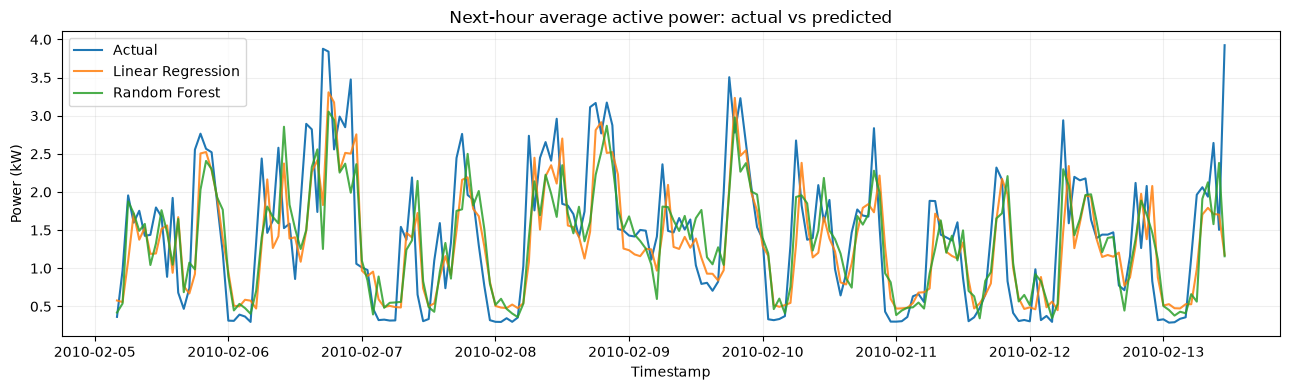

In [17]:
n = min(200, len(y_test))
plt.figure(figsize=(13, 4))
plt.plot(y_test.index[:n], y_test.iloc[:n].to_numpy(), label="Actual", linewidth=1.5)
for name in ["Linear Regression", "Random Forest"]:
    plt.plot(y_test.index[:n], predictions[name][:n], label=name, alpha=0.85)
plt.title("Next-hour average active power: actual vs predicted")
plt.ylabel("Power (kW)"); plt.xlabel("Timestamp"); plt.legend(); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

## 7.paired error comparison: Linear Regression vs Random Forest

In [18]:
linear_abs_error = np.abs(y_test.to_numpy() - predictions["Linear Regression"])
forest_abs_error = np.abs(y_test.to_numpy() - predictions["Random Forest"])
t_stat, p_value = ttest_rel(linear_abs_error, forest_abs_error)
print(f"Mean absolute error — Linear Regression: {linear_abs_error.mean():.4f} kW")
print(f"Mean absolute error — Random Forest: {forest_abs_error.mean():.4f} kW")
print(f"Paired t-test t-statistic: {t_stat:.4f}; p-value: {p_value:.6g}")
print("At alpha=0.05, reject equal mean absolute errors." if p_value < 0.05 else "At alpha=0.05, do not reject equal mean absolute errors.")
print("Caution: paired t-test assumptions and time-series error dependence should be considered when interpreting this result.")

Mean absolute error — Linear Regression: 0.4030 kW
Mean absolute error — Random Forest: 0.3908 kW
Paired t-test t-statistic: 4.2714; p-value: 1.96901e-05
At alpha=0.05, reject equal mean absolute errors.
Caution: paired t-test assumptions and time-series error dependence should be considered when interpreting this result.


## 8. Forecast several hours from a selected real timestamp
The code predicts one step, updates the power feature with that prediction, and repeats. Other future measurements are unavailable, so the remaining features are held constant. This is an educational recursive baseline; it can flatten or drift and should not be treated as a fully validated multi-step forecast.

,Forecast time,Predicted average power (kW),Estimated energy (kWh)
0,2010-11-26 22:00:00,1.528249,1.528249
1,2010-11-26 23:00:00,1.405677,1.405677
2,2010-11-27 00:00:00,1.405677,1.405677
3,2010-11-27 01:00:00,1.405677,1.405677
4,2010-11-27 02:00:00,1.405677,1.405677
5,2010-11-27 03:00:00,1.405677,1.405677
6,2010-11-27 04:00:00,1.405677,1.405677
7,2010-11-27 05:00:00,1.405677,1.405677
8,2010-11-27 06:00:00,1.405677,1.405677
9,2010-11-27 07:00:00,1.405677,1.405677


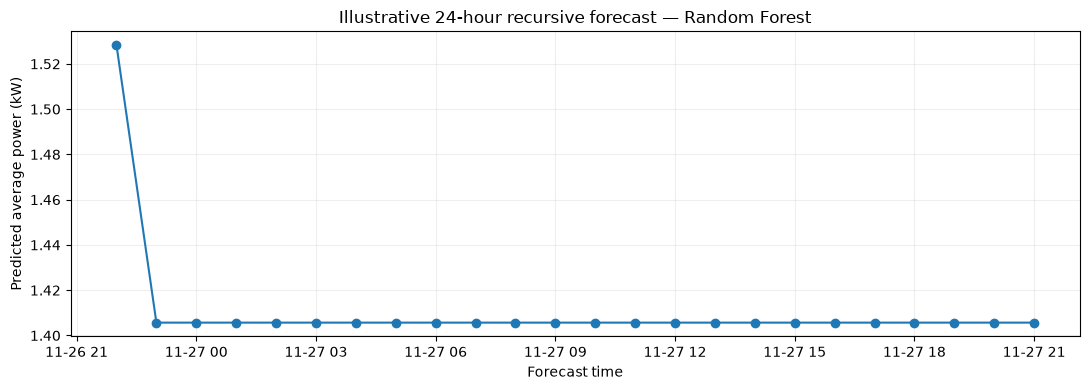

In [19]:
def forecast_hours(model, start_row, start_time, hours=24):
    current = start_row[FEATURES].iloc[0].astype(float).to_dict()
    output = []
    for step in range(1, hours + 1):
        next_power = max(0.0, float(model.predict(pd.DataFrame([current], columns=FEATURES))[0]))
        output.append({"Forecast time": start_time + pd.Timedelta(hours=step),
                       "Predicted average power (kW)": next_power,
                       "Estimated energy (kWh)": next_power})
        current["power_kw"] = next_power
    return pd.DataFrame(output)

# Change this to any timestamp available in hourly.index to inspect another historical starting point.
start_time = hourly.index[-1]
start_row = hourly.loc[[start_time], FEATURES]
chosen_model = models[best_model_name]
forecast = forecast_hours(chosen_model, start_row, start_time, hours=24)
display(forecast.head(10))
plt.figure(figsize=(11, 4))
plt.plot(forecast["Forecast time"], forecast["Predicted average power (kW)"], marker="o")
plt.title(f"Illustrative 24-hour recursive forecast — {best_model_name}")
plt.ylabel("Predicted average power (kW)"); plt.xlabel("Forecast time"); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

## 9. Estimate energy and bill
For hourly predictions, kWh for each hour is approximately the predicted average kW multiplied by one hour. The total estimated charge is total kWh multiplied by the assumed tariff.

In [20]:
tariff_per_kwh = 8.0  # Change to your assumed tariff in ₹ per unit
estimated_units = forecast["Estimated energy (kWh)"].sum()
estimated_cost = estimated_units * tariff_per_kwh
print(f"Estimated energy over {len(forecast)} hours: {estimated_units:.2f} kWh (units)")
print(f"Assumed tariff: ₹{tariff_per_kwh:.2f}/kWh")
print(f"Estimated energy charge: ₹{estimated_cost:.2f}")

Estimated energy over 24 hours: 33.86 kWh (units)
Assumed tariff: ₹8.00/kWh
Estimated energy charge: ₹270.87


## 10. Correlation and dataset notes

,count,mean,std,min,25%,50%,75%,max
power_kw,34168.0,1.091728,0.897619,0.124000,0.341925,0.802850,1.579342,6.560533
reactive_power,34168.0,0.123727,0.066851,0.000000,0.078000,0.106917,0.149433,0.774333
voltage,34168.0,240.839393,3.001093,225.834500,239.180667,240.977833,242.695000,251.902000
intensity,34168.0,4.628238,3.757797,0.503333,1.513333,3.423333,6.606667,28.383333
kitchen_submeter_wh,34168.0,67.289130,212.256591,0.000000,0.000000,0.000000,0.000000,2902.000000
laundry_submeter_wh,34168.0,77.880795,251.538667,0.000000,0.000000,20.000000,39.000000,2786.000000
water_heater_ac_submeter_wh,34168.0,387.355625,440.945119,0.000000,39.000000,99.000000,853.000000,1293.000000


AttributeError: Text.set() got an unexpected keyword argument 'annot'

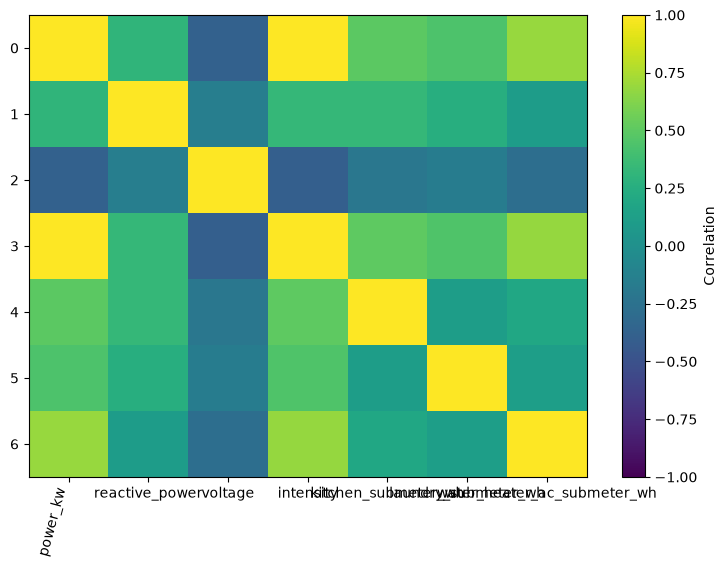

In [21]:
display(hourly[FEATURES].describe().T)
plt.figure(figsize=(9, 6))
correlation = hourly[FEATURES].corr()
plt.imshow(correlation, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(FEATURES)), FEATURES, rotation=75, ha="right",annot=True)
plt.yticks(range(len(FEATURES)), FEATURES)
plt.title("Feature correlation matrix")
plt.tight_layout(); plt.show()

# Export the processed hourly measurements for the Streamlit app or further analysis.
hourly.to_csv("uci_household_hourly.csv", index_label="datetime")
print("Saved uci_household_hourly.csv in the current working directory")

In [ ]:
!pip install joblib

In [ ]:
import joblib
from google.colab import files

filename = "electricity_prediction_models.joblib"
joblib.dump(models, filename)

print("All trained models saved successfully!")

files.download(filename)

All trained models saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>